<a href="https://colab.research.google.com/github/biswasan/payment-data-quality-pipeline/blob/main/payment_showcase.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Payment data quality
Synthetic data. Run all cells: inspect SQL, run cleaning, view Python chart. Expected: 12 input, 5 accepted, 6 review, 1 duplicate; $3,200 validated.

In [ ]:
from pathlib import Path
BASE = Path.cwd()
(BASE / 'messy_payments.csv').write_text('source_row,payment_id,department,payment_date,amount\n1,101, Health ,2026-09-01,1200\n2,101,health,2026-09-01,1200.00\n3,102,TRANSPORT,2026-09-02,850\n4,103,Health,2026-09-03,unknown\n5,104,Education,2026-09-04,500\n6,105,Health,2026-09-05,-75\n7,106,Transport,2026-02-30,300\n8,107,Education,2026-09-06,200\n9,107,Education,2026-09-06,250\n10,108,Health,2026-09-07,0\n11,,Health,2026-09-08,100\n12,109,Education,2026-09-08,650\n')


416

## SQL: inspect the cleaning rules

In [ ]:
from pathlib import Path
from urllib.request import urlopen

url = "https://raw.githubusercontent.com/biswasan/payment-data-quality-pipeline/main/clean_payments.sql"

sql = urlopen(url).read().decode("utf-8")
Path("clean_payments.sql").write_text(sql, encoding="utf-8")

print(sql)

DROP TABLE IF EXISTS Patient_Table; -- 1

CREATE TABLE Patient_Table AS
SELECT *,
       NULLIF(TRIM(payment_id), '') AS business_id,
       LOWER(TRIM(department)) AS clean_department,
       valid_date(payment_date) AS clean_date,
       cents(amount) AS amount_cents
FROM raw_patients;


DROP TABLE IF EXISTS ranked; -- 2

CREATE TABLE ranked AS
SELECT *,
       ROW_NUMBER() OVER (
           PARTITION BY
               business_id,
               clean_department,
               payment_date,
               amount_cents,
               CASE
                   WHEN amount_cents IS NULL THEN amount
                   ELSE ''
               END
           ORDER BY CAST(source_row AS INTEGER)
       ) AS duplicate_rank
FROM Patient_Table;


DROP TABLE IF EXISTS duplicate_log; -- 3

CREATE TABLE duplicate_log AS
SELECT *
FROM ranked
WHERE duplicate_rank > 1;


DROP TABLE IF EXISTS conflicts; -- 4

CREATE TABLE conflicts AS
SELECT business_id
FROM ranked
WHERE duplicate_rank = 1
  AND busi

## Python: run the pipeline and display the chart

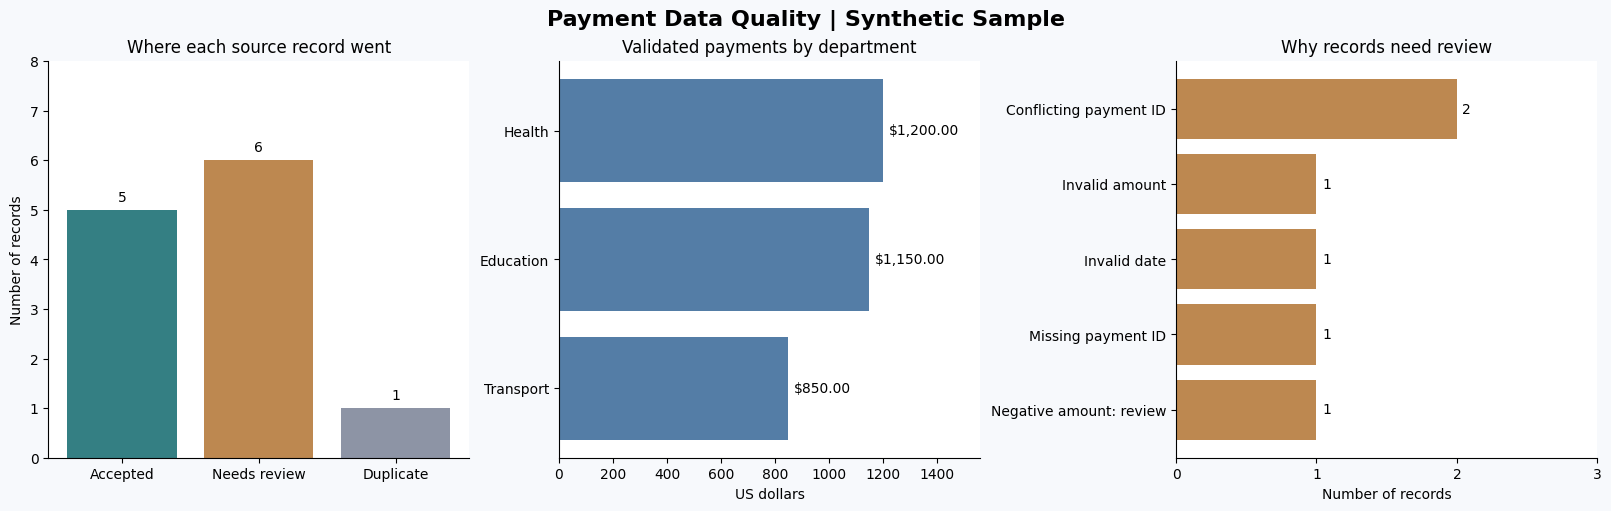

Input records: 12
Accepted records: 5
Records needing review: 6
Duplicates removed: 1
Validated payment total: $3,200.00
All validation checks passed.


{'__name__': '__main__',
 '__doc__': None,
 '__package__': '',
 '__loader__': None,
 '__spec__': None,
 '__file__': 'pipeline.py',
 '__cached__': None,
 '__builtins__': {'__name__': 'builtins',
  '__doc__': "Built-in functions, types, exceptions, and other objects.\n\nThis module provides direct access to all 'built-in'\nidentifiers of Python; for example, builtins.len is\nthe full name for the built-in function len().\n\nThis module is not normally accessed explicitly by most\napplications, but can be useful in modules that provide\nobjects with the same name as a built-in value, but in\nwhich the built-in of that name is also needed.",
  '__package__': '',
  '__loader__': _frozen_importlib.BuiltinImporter,
  '__spec__': ModuleSpec(name='builtins', loader=<class '_frozen_importlib.BuiltinImporter'>, origin='built-in'),
  '__build_class__': <function __build_class__>,
  '__import__': <function __import__(name, globals=None, locals=None, fromlist=(), level=0)>,
  'abs': <function abs(x,

In [ ]:
from pathlib import Path
from urllib.request import urlopen
import runpy

base_url = "https://raw.githubusercontent.com/biswasan/payment-data-quality-pipeline/main/"

for filename in ["messy_payments.csv", "clean_payments.sql", "pipeline.py"]:
    data = urlopen(base_url + filename).read()
    Path(filename).write_bytes(data)

runpy.run_path("pipeline.py", run_name="__main__")

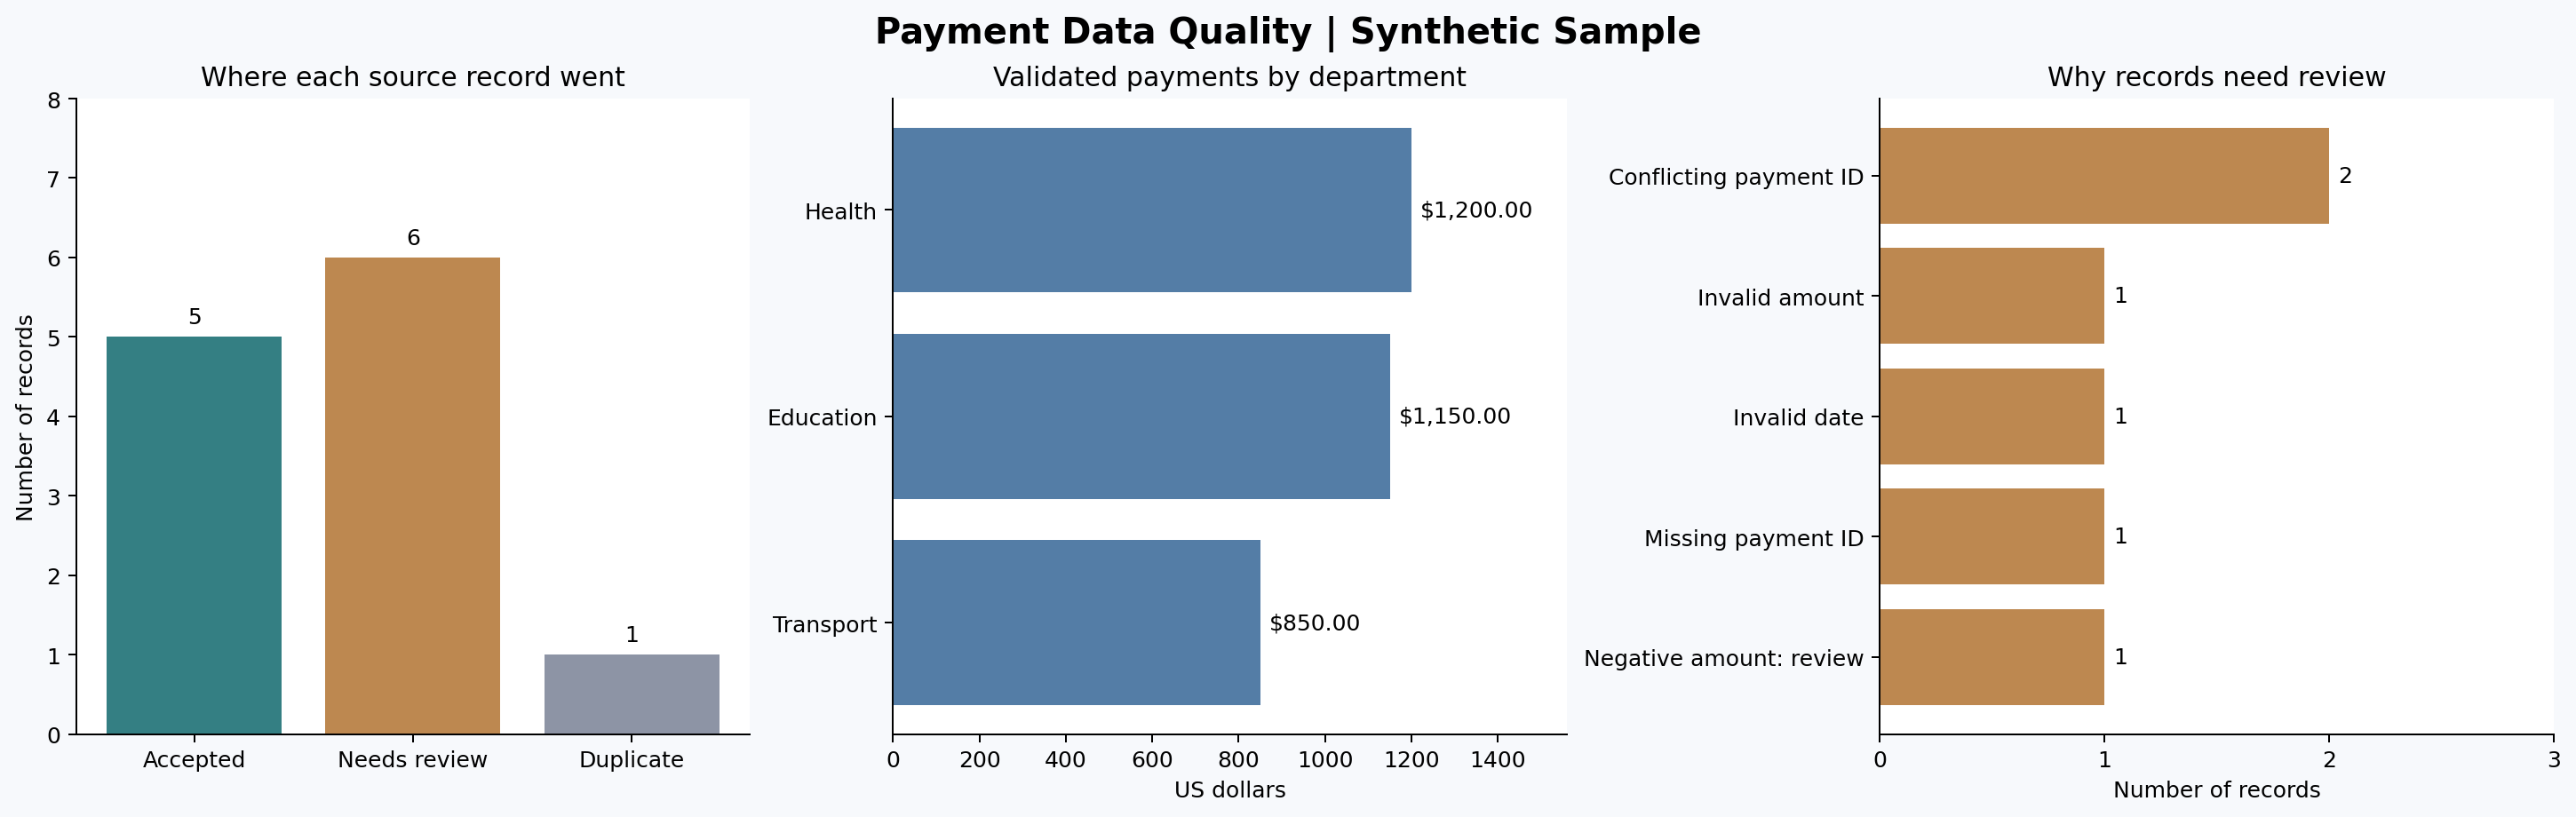

In [ ]:
from pathlib import Path
from IPython.display import display, Image

chart = Path("outputs/payment_quality.png")

if chart.exists():
    display(Image(filename=str(chart)))
else:
    print("The chart file was not created. Check the previous cell for an error.")